O lançamento de projéteis é um problema clássico da Mecânica que descreve o movimento de um objeto lançado com uma velocidade inicial formando um ângulo com a horizontal. Esse movimento pode ser decomposto em duas dimensões independentes: a horizontal, com velocidade constante, e a vertical, com aceleração constante devido à gravidade.

Neste trabalho, vou considerar a resistência do ar desprezível, a aceleração da gravidade constante ($9.81 m/s^2$) e o lançamento e a queda ocorrendo na mesma altura.
O projétil parte da origem do sistema de coordenadas, isto é, $(x_0, y_0) = (0, 0)$.

As equações do movimento são, portanto:

$$
x(t) = v_0 \cos(\theta)t
$$

$$
y(t) = v_0 \sin(\theta)t - \frac{1}{2}gt^2
$$

O objetivo deste programa é calcular as posições horizontal e vertical do projétil em função do tempo, além do tempo de voo, a altura máxima e o alcance horizontal para uma velocidade e um ângulo determinados ao criar o objeto. Adicionalmente, o programa investigará qual ângulo de lançamento produz o maior alcance, comparando o resultado numérico com a previsão teórica.

Utilizarei as seguintes equações:

Tempo de Voo

$$
t_{voo} = \frac{2v_0\sin(\theta)}{g}
$$

Alcance Horizontal

$$
r = \frac{v_0^2\sin(2\theta)}{g}
$$

Altura Máxima

$$
h_{\max} = \frac{v_0^2\sin^2(\theta)}{2g}
$$

In [54]:
import math
import numpy as np
import matplotlib.pyplot as plt

In [23]:
class Projetil:
    def __init__(self, v0, angulo, g=9.81):
        self.v0 = v0
        self.angulo = angulo
        self.g = g

    def posicao_x(self, t):

        x = self.v0 * math.cos(math.radians(self.angulo)) * t

        return x

    def posicao_y(self, t):

        y = self.v0 * math.sin(math.radians(self.angulo)) * t - (self.g * t**2) / 2

        return y

    def tempo_voo(self):

        t_voo = (2 * self.v0 * math.sin(math.radians(self.angulo))) / self.g

        return t_voo

    def altura_max(self):

        h_max = ((self.v0**2) * math.sin(math.radians(self.angulo))**2) / (2 * self.g)

        return h_max

    def alcance(self):

        r = ((self.v0**2) * math.sin(math.radians(2 * self.angulo))) / self.g

        return r

In [80]:
p = Projetil(20, 45)

t_voo = p.tempo_voo()
x_t = p.posicao_x(p.tempo_voo())
y_t = p.posicao_y(p.tempo_voo())
h_max = p.altura_max()
r = p.alcance()
print(f"Posição Horizontal: {x_t:.2f} m")
print(f"Posição Vertical: {y_t:.2f} m")
print(f"Tempo de Voo: {t_voo:.2f} s")
print(f"Altura Máxima: {h_max:.2f} m")
print(f"Alcance Horizontal: {r:.2f} m")


Posição Horizontal: 40.77 m
Posição Vertical: 0.00 m
Tempo de Voo: 2.88 s
Altura Máxima: 10.19 m
Alcance Horizontal: 40.77 m


### Gráfico da trajetória do projétil

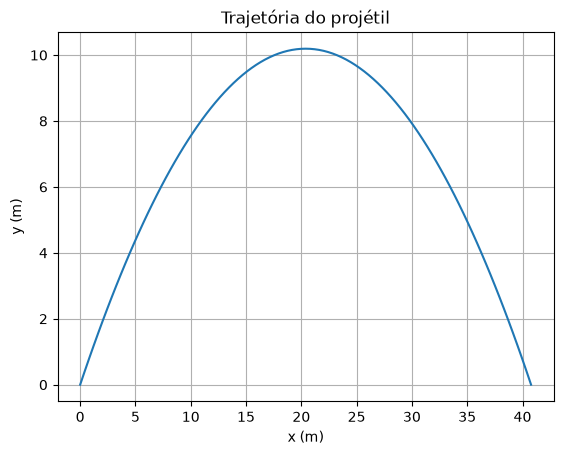

<Figure size 640x480 with 0 Axes>

In [68]:
tempos = np.linspace(0, p.tempo_voo(),101)

x = [p.posicao_x(t) for t in tempos]
y = [p.posicao_y(t) for t in tempos]

plt.plot(x, y)
plt.xlabel("x (m)")
plt.ylabel("y (m)")
plt.grid(True)
plt.title("Trajetória do projétil")
plt.figure()

plt.show()

### Gráfico do alcance em função do ângulo de lançamento

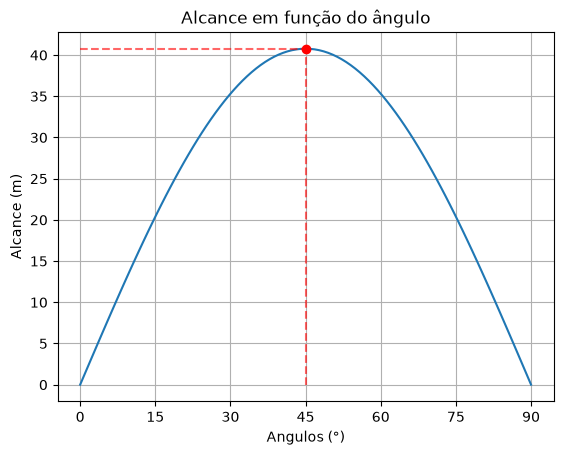

In [69]:
angulos = np.linspace(0, 90, 101)

alcances = [Projetil(20, angulo).alcance() for angulo in angulos]

plt.figure()
plt.plot(angulos, alcances)
plt.xlabel("Angulos (°)")
plt.xticks(np.arange(0,91,15))
plt.ylabel("Alcance (m)")
plt.grid(True)
plt.title("Alcance em função do ângulo")

indice_max = alcances.index(max(alcances))
angulo_max = angulos[indice_max]
alcance_max = alcances[indice_max]

plt.scatter(angulo_max, alcance_max, color = 'red', zorder=5)
plt.plot([angulo_max, angulo_max], [0, alcance_max], 'r--', alpha=0.6)
plt.plot([0,angulo_max], [alcance_max, alcance_max], 'r--', alpha=0.6)

plt.show()

### Comparação das trajetórias para diferentes ângulos

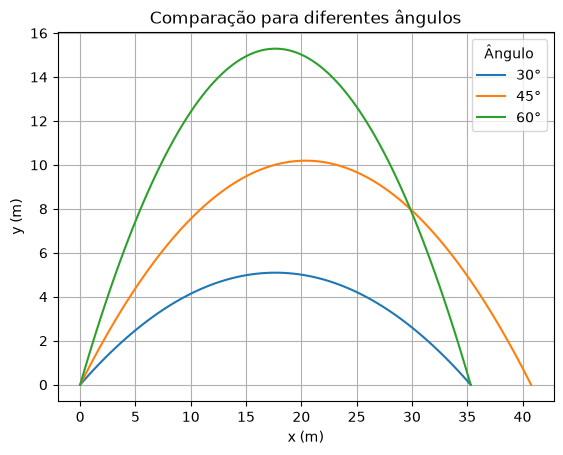

In [73]:
angulos_comparacao = [30, 45, 60]

plt.figure()

for angulo in angulos_comparacao:

    p_a = Projetil(20, angulo)
    tempos = np.linspace(0, p_a.tempo_voo(), 100)

    x_a = [p_a.posicao_x(t) for t in tempos]
    y_a = [p_a.posicao_y(t) for t in tempos]

    plt.plot(x_a, y_a, label=f"{angulo}°")

plt.xlabel("x (m)")
plt.ylabel("y (m)")
plt.title("Comparação para diferentes ângulos")
plt.legend(title = "Ângulo")
plt.grid(True)

plt.show()

### Conclusão

Neste trabalho, foi desenvolvido um programa em Python para simular o lançamento de projéteis, utilizando uma classe que calcula as posições horizontal e vertical, o tempo de voo, a altura máxima e o alcance horizontal. A partir desses cálculos, foram construídos gráficos para visualizar a trajetória do projétil, analisar a variação do alcance com o ângulo de lançamento e comparar trajetórias para diferentes ângulos.

Os resultados mostram que, desprezando a resistência do ar e considerando que o projétil parte e chega à mesma altura, o alcance horizontal máximo ocorre para um ângulo de lançamento de 45°. Isso está de acordo com a previsão teórica, obtida pela expressão $r = \frac{v_0^2\sin(2\theta)}{g}$, cujo valor máximo ocorre quando $\sin(2\theta)=1$.